# JRT results: graded response model, model ladder and reliability

Display notebook for the manuscript. It fits nothing: it shows the CSV and figure
outputs of the R pipeline in `../R/` (`01_data_design.R` … `06_summary.R`, run on the
server, see `../server/README.md` and `../AUDIT.md`) as labelled tables and figures,
so the manuscript can embed them. Re-execute it (seconds) after every pipeline run.
Objects whose source file does not exist yet show a placeholder line.

Numbers in the text come from these tables through the results-interpreter.

In [1]:
from pathlib import Path

import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.image as mpimg
from IPython.display import Markdown

RES = Path("..").resolve() / "results"

def _missing(path):
    return Markdown(f"_Not available yet: `results/{path}` (run the R pipeline)._")

def read_res(path):
    f = RES / path
    return pd.read_csv(f) if f.exists() else None

def show_table(path, fn=None, digits=3):
    # Markdown table without the index column, for embedding in the manuscript.
    df = read_res(path)
    if df is None:
        return _missing(path)
    if fn is not None:
        df = fn(df)
    return Markdown(df.to_markdown(index=False, floatfmt=f".{digits}f"))

def show_png(path, width=8):
    f = RES / path
    if not f.exists():
        return _missing(path)
    img = mpimg.imread(f)
    fig, ax = plt.subplots(figsize=(width, width * img.shape[0] / img.shape[1]))
    ax.imshow(img)
    ax.axis("off")
    fig.tight_layout(pad=0)
    plt.show()

## 1. Data and design

In [2]:
#| label: tbl-design-summary
#| tbl-cap: "Data basis shared by all models: ratings, products, raters, coverage of the product x rater matrix and connectivity of the design."
show_table("data/design_summary.csv", lambda d: d[d["quantity"] != "data_fingerprint"])

| quantity                          | value              |
|:----------------------------------|:-------------------|
| n_ratings                         | 7844               |
| n_products                        | 3669               |
| n_raters                          | 22                 |
| n_categories                      | 7                  |
| scale                             | 1-7                |
| internal_coding                   | rating - 1 (0-6)   |
| ratings_per_product_mean          | 2.13791223766694   |
| ratings_per_product_median        | 2                  |
| ratings_per_product_min           | 1                  |
| ratings_per_product_max           | 12                 |
| ratings_per_product_harmonic_mean | 1.72632034132518   |
| products_with_1_rating            | 898                |
| ratings_per_rater_min             | 2                  |
| ratings_per_rater_max             | 1174               |
| matrix_fill                       | 0.0971778289848609 |
| n_components                      | 1                  |
| rater_pairs_total                 | 231                |
| rater_pairs_without_overlap       | 37                 |
| rater_pairs_overlap_median        | 7                  |
| raters_with_category_gaps         | 8                  |
| raters_with_internal_gap          | 2                  |
| duplicate_pairs_resolved_in_00    | 12                 |
| duplicate_pairs_conflicting       | 1                  |

In [3]:
#| label: tbl-category-usage
#| tbl-cap: "Category use per rater (counts of ratings 1-7). Unused categories at the ends of the scale reduce the number of thresholds of a rater; an unused category inside the observed range (internal gap) makes that rater's thresholds incomparable with those of other raters."
show_table("data/category_usage.csv", lambda d: d[["rater_id"] + [c for c in d if c.startswith("cat_")] + ["n_ratings", "missing_categories", "internal_gap"]])

| rater_id   |   cat_1 |   cat_2 |   cat_3 |   cat_4 |   cat_5 |   cat_6 |   cat_7 |   n_ratings | missing_categories   | internal_gap   |
|:-----------|--------:|--------:|--------:|--------:|--------:|--------:|--------:|------------:|:---------------------|:---------------|
| R01        |     337 |     461 |     259 |      87 |      24 |       6 |       0 |        1174 | 7                    | False          |
| R02        |     241 |     179 |     124 |     126 |      91 |      67 |      45 |         873 | nan                  | False          |
| R03        |     161 |     182 |     185 |      82 |      88 |      22 |       0 |         720 | 7                    | False          |
| R04        |     164 |     164 |      90 |      69 |      92 |      36 |       5 |         620 | nan                  | False          |
| R05        |     159 |     190 |     102 |      90 |      50 |      30 |      12 |         633 | nan                  | False          |
| R06        |     301 |     113 |      57 |      34 |       9 |       6 |       0 |         520 | 7                    | False          |
| R07        |     183 |     152 |      96 |      61 |      36 |      17 |       2 |         547 | nan                  | False          |
| R08        |     101 |     127 |     106 |      91 |      60 |      30 |       7 |         522 | nan                  | False          |
| R09        |      63 |      62 |      72 |      60 |      66 |      55 |      22 |         400 | nan                  | False          |
| R10        |      25 |     156 |      76 |      64 |      47 |      13 |       2 |         383 | nan                  | False          |
| R11        |     127 |     118 |      51 |      31 |      32 |       9 |       1 |         369 | nan                  | False          |
| R12        |      11 |      48 |      90 |      77 |      27 |      10 |       1 |         264 | nan                  | False          |
| R13        |       4 |      35 |      68 |      91 |      44 |      11 |       1 |         254 | nan                  | False          |
| R14        |     105 |      66 |      40 |      31 |      10 |       5 |       2 |         259 | nan                  | False          |
| R15        |       7 |      22 |      11 |       9 |      13 |       9 |       2 |          73 | nan                  | False          |
| R16        |       4 |      14 |       9 |      14 |       5 |       3 |       3 |          52 | nan                  | False          |
| R17        |      25 |      10 |       9 |       4 |       4 |       0 |       0 |          52 | 6;7                  | False          |
| R18        |       1 |       8 |      14 |      12 |      16 |       4 |       0 |          55 | 7                    | False          |
| R19        |      10 |       6 |       8 |       6 |      10 |       6 |       4 |          50 | nan                  | False          |
| R20        |       4 |       0 |       1 |       4 |       2 |       2 |       0 |          13 | 2;7                  | True           |
| R21        |       1 |       2 |       3 |       1 |       2 |       0 |       0 |           9 | 6;7                  | False          |
| R22        |       0 |       1 |       0 |       1 |       0 |       0 |       0 |           2 | 1;3;5;6;7            | True           |

## 2. Graded response model (central model)

In [4]:
#| label: tbl-grm-convergence
#| tbl-cap: "Estimation and convergence of the graded response model (marginal maximum likelihood, EM algorithm, fixed quadrature)."
show_table("grm/convergence.csv", lambda d: d[["method", "quadpts", "se_type", "tol", "converged", "iterations", "information_matrix_pd", "logLik", "npar", "AIC", "BIC", "SABIC", "n_products", "n_ratings"]])

| method   |   quadpts | se_type   |   tol | converged   |   iterations | information_matrix_pd   |     logLik |   npar |       AIC |       BIC |     SABIC |   n_products |   n_ratings |
|:---------|----------:|:----------|------:|:------------|-------------:|:------------------------|-----------:|-------:|----------:|----------:|----------:|-------------:|------------:|
| EM       |        61 | Oakes     | 0.000 | True        |          144 | True                    | -11765.852 |    139 | 23809.703 | 24672.570 | 24230.896 |         3669 |        7844 |

In [5]:
#| label: tbl-grm-rater-parameters
#| tbl-cap: "Rater parameters of the graded response model in IRT metric: discrimination a and thresholds b_k with standard errors; category_boundaries states which rating categories each threshold separates."
show_table("grm/rater_parameters.csv", lambda d: d[["rater_id", "n_ratings", "a", "a_se"] + [c for c in d if c[0] == "b" and c[1:].isdigit()] + ["category_boundaries", "thresholds_ordered"]])

| rater_id   |   n_ratings |      a |   a_se |     b1 |      b2 |      b3 |      b4 |      b5 |      b6 | category_boundaries     | thresholds_ordered   |
|:-----------|------------:|-------:|-------:|-------:|--------:|--------:|--------:|--------:|--------:|:------------------------|:---------------------|
| R01        |        1174 |  1.954 |  0.159 | -0.774 |   0.579 |   1.731 |   2.751 |   3.792 | nan     | 1|2;2|3;3|4;4|5;5|6     | True                 |
| R02        |         873 |  2.480 |  0.326 | -0.708 |  -0.035 |   0.400 |   0.905 |   1.404 |   2.035 | 1|2;2|3;3|4;4|5;5|6;6|7 | True                 |
| R03        |         720 |  1.944 |  0.197 | -1.086 |  -0.152 |   0.751 |   1.275 |   2.452 | nan     | 1|2;2|3;3|4;4|5;5|6     | True                 |
| R04        |         620 |  2.046 |  0.246 | -0.764 |   0.168 |   0.661 |   1.098 |   2.043 |   3.410 | 1|2;2|3;3|4;4|5;5|6;6|7 | True                 |
| R05        |         633 |  2.199 |  0.226 | -0.828 |   0.165 |   0.720 |   1.362 |   1.965 |   2.828 | 1|2;2|3;3|4;4|5;5|6;6|7 | True                 |
| R06        |         520 |  2.792 |  0.420 |  0.295 |   1.047 |   1.626 |   2.319 |   2.776 | nan     | 1|2;2|3;3|4;4|5;5|6     | True                 |
| R07        |         547 |  1.989 |  0.199 | -0.539 |   0.401 |   1.069 |   1.706 |   2.466 |   3.872 | 1|2;2|3;3|4;4|5;5|6;6|7 | True                 |
| R08        |         522 |  2.173 |  0.287 | -1.162 |  -0.293 |   0.367 |   1.064 |   1.850 |   2.939 | 1|2;2|3;3|4;4|5;5|6;6|7 | True                 |
| R09        |         400 |  0.863 |  0.151 | -2.207 |  -1.078 |  -0.081 |   0.747 |   1.880 |   3.676 | 1|2;2|3;3|4;4|5;5|6;6|7 | True                 |
| R10        |         383 |  2.241 |  0.343 | -2.036 |  -0.172 |   0.475 |   1.137 |   2.115 |   3.375 | 1|2;2|3;3|4;4|5;5|6;6|7 | True                 |
| R11        |         369 |  1.819 |  0.213 | -0.529 |   0.599 |   1.184 |   1.696 |   2.730 |   4.169 | 1|2;2|3;3|4;4|5;5|6;6|7 | True                 |
| R12        |         264 |  2.920 |  0.576 | -2.003 |  -0.895 |   0.159 |   1.270 |   2.128 |   3.415 | 1|2;2|3;3|4;4|5;5|6;6|7 | True                 |
| R13        |         254 |  1.513 |  0.224 | -3.371 |  -1.499 |  -0.260 |   1.195 |   2.631 |   4.415 | 1|2;2|3;3|4;4|5;5|6;6|7 | True                 |
| R14        |         259 |  2.784 |  0.683 | -0.194 |   0.537 |   1.074 |   1.800 |   2.346 |   3.068 | 1|2;2|3;3|4;4|5;5|6;6|7 | True                 |
| R15        |          73 |  2.479 |  0.517 | -1.710 |  -0.253 |   0.253 |   0.661 |   1.337 |   2.667 | 1|2;2|3;3|4;4|5;5|6;6|7 | True                 |
| R16        |          52 |  3.899 |  1.526 | -1.330 |  -0.252 |   0.211 |   1.167 |   1.735 |   2.223 | 1|2;2|3;3|4;4|5;5|6;6|7 | True                 |
| R17        |          52 |  1.446 |  0.465 | -0.183 |   0.550 |   1.350 |   2.005 | nan     | nan     | 1|2;2|3;3|4;4|5         | True                 |
| R18        |          55 |  0.645 |  0.266 | -6.436 |  -2.712 |  -0.567 |   0.952 |   4.356 | nan     | 1|2;2|3;3|4;4|5;5|6     | True                 |
| R19        |          50 |  3.764 |  2.327 | -0.934 |  -0.584 |  -0.141 |   0.197 |   0.928 |   1.688 | 1|2;2|3;3|4;4|5;5|6;6|7 | True                 |
| R20        |          13 |  1.039 |  0.676 | -0.829 |  -0.419 |   1.010 |   1.992 | nan     | nan     | 1|3;3|4;4|5;5|6         | True                 |
| R21        |           9 | -0.085 |  1.011 | 24.541 |   8.213 |  -8.088 | -14.631 | nan     | nan     | 1|2;2|3;3|4;4|5         | False                |
| R22        |           2 | -3.861 |  7.832 |  0.831 | nan     | nan     | nan     | nan     | nan     | 2|4                     | True                 |

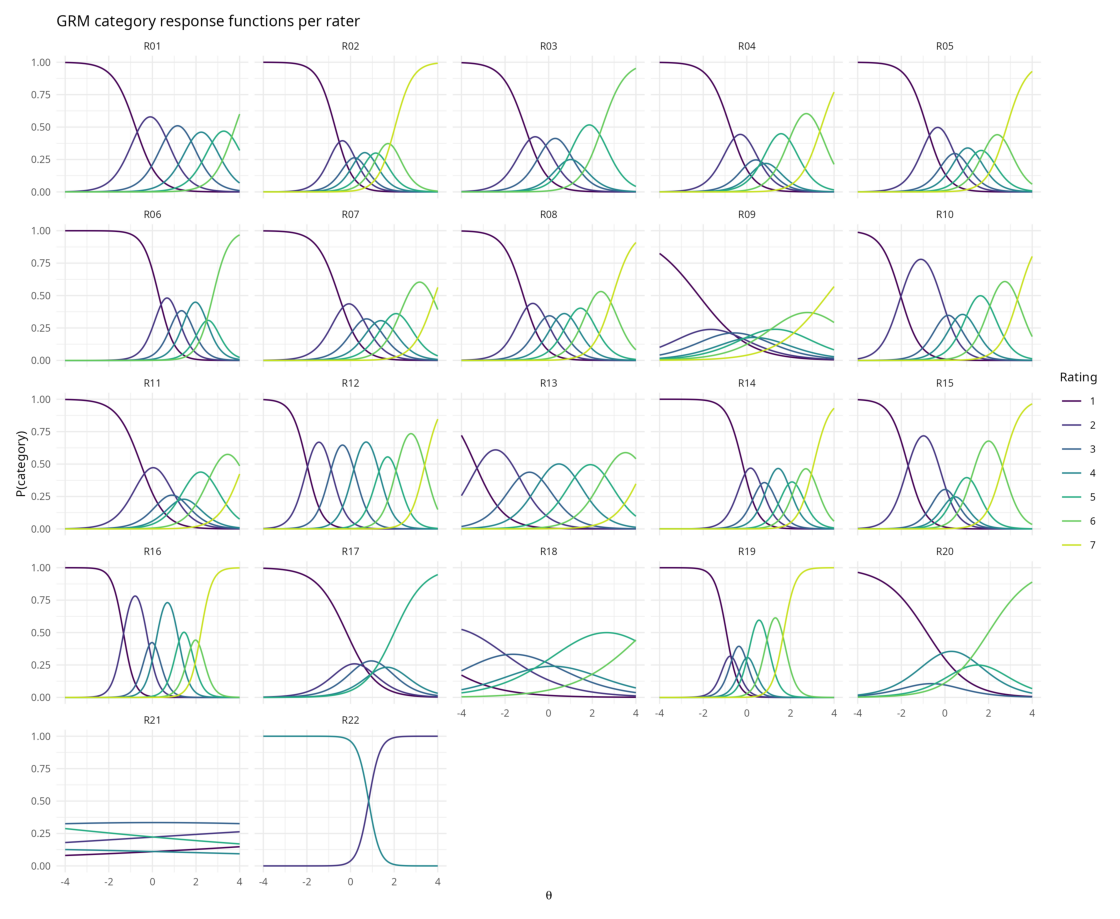

In [6]:
#| label: fig-grm-category-response-functions
#| fig-cap: "Category response functions of the graded response model for each rater."
show_png("grm/figures/grm_category_response_functions.png", width=11)

In [7]:
#| label: tbl-grm-rater-fit
#| tbl-cap: "Rater fit in the graded response model: infit and outfit mean squares (observed ratings) and S-X2 pooled over multiple imputations of the missing ratings."
show_table("grm/rater_fit.csv", lambda d: d[["rater_id", "n_ratings", "infit", "outfit", "S_X2", "df_S_X2", "p_S_X2", "n_imputations"]])

| rater_id   |   n_ratings |   infit |   outfit |    S_X2 |   df_S_X2 |   p_S_X2 |   n_imputations |
|:-----------|------------:|--------:|---------:|--------:|----------:|---------:|----------------:|
| R01        |        1174 |   0.680 |    0.651 | 209.726 |   218.450 |    0.652 |              20 |
| R02        |         873 |   0.453 |    0.427 | 301.168 |   308.500 |    0.607 |              20 |
| R03        |         720 |   0.699 |    0.687 | 289.128 |   288.100 |    0.472 |              20 |
| R04        |         620 |   0.586 |    0.553 | 299.982 |   297.550 |    0.450 |              20 |
| R05        |         633 |   0.618 |    0.578 | 300.008 |   304.150 |    0.556 |              20 |
| R06        |         520 |   0.607 |    0.469 | 192.134 |   197.500 |    0.594 |              20 |
| R07        |         547 |   0.724 |    0.646 | 292.675 |   293.050 |    0.495 |              20 |
| R08        |         522 |   0.584 |    0.570 | 297.552 |   293.000 |    0.415 |              20 |
| R09        |         400 |   0.871 |    0.870 | 450.108 |   449.150 |    0.478 |              20 |
| R10        |         383 |   0.623 |    0.602 | 264.016 |   258.300 |    0.390 |              20 |
| R11        |         369 |   0.829 |    0.783 | 288.067 |   302.200 |    0.711 |              20 |
| R12        |         264 |   0.506 |    0.503 | 200.739 |   203.200 |    0.536 |              20 |
| R13        |         254 |   0.830 |    0.832 | 276.997 |   275.800 |    0.468 |              20 |
| R14        |         259 |   0.479 |    0.394 | 233.767 |   236.650 |    0.541 |              20 |
| R15        |          73 |   0.761 |    0.667 | 267.564 |   270.350 |    0.536 |              20 |
| R16        |          52 |   0.492 |    0.460 | 210.878 |   207.700 |    0.426 |              20 |
| R17        |          52 |   0.925 |    0.824 | 288.471 |   284.700 |    0.427 |              20 |
| R18        |          55 |   0.970 |    0.960 | 350.103 |   350.250 |    0.492 |              20 |
| R19        |          50 |   0.330 |    0.318 | 234.333 |   234.450 |    0.490 |              20 |
| R20        |          13 |   0.921 |    0.910 | 304.574 |   296.700 |    0.364 |              20 |
| R21        |           9 |   1.002 |    1.002 | 344.065 |   341.800 |    0.455 |              20 |
| R22        |           2 |   0.317 |    0.316 |  53.434 |    54.300 |    0.508 |              20 |

In [8]:
#| label: tbl-grm-q3-flagged
#| tbl-cap: "Rater pairs with the largest local dependence (Q3 minus mean Q3) among pairs with at least 30 jointly rated products."
show_table("grm/q3.csv", lambda d: d[d["n_common"] >= 30].assign(_a=lambda x: x["q3_minus_mean"].abs()).sort_values("_a", ascending=False).drop(columns="_a").head(10))

| rater_1   | rater_2   |   n_common |     q3 |   q3_minus_mean |   overlap_flag | flag_q3   |
|:----------|:----------|-----------:|-------:|----------------:|---------------:|:----------|
| R08       | R19       |         46 | -0.766 |          -0.563 |            nan | True      |
| R08       | R12       |         51 | -0.746 |          -0.543 |            nan | True      |
| R02       | R14       |        108 | -0.621 |          -0.418 |            nan | True      |
| R03       | R10       |         49 | -0.615 |          -0.412 |            nan | True      |
| R01       | R10       |        157 | -0.613 |          -0.411 |            nan | True      |
| R02       | R04       |        257 | -0.609 |          -0.406 |            nan | True      |
| R02       | R08       |         72 | -0.588 |          -0.385 |            nan | True      |
| R01       | R08       |        191 | -0.569 |          -0.366 |            nan | True      |
| R04       | R14       |         47 | -0.565 |          -0.363 |            nan | True      |
| R11       | R14       |         33 | -0.524 |          -0.321 |            nan | True      |

In [9]:
#| label: tbl-grm-global-fit
#| tbl-cap: "Limited-information absolute fit of the graded response model (C2)."
show_table("grm/global_fit.csv", lambda d: d.drop(columns=["q3_mirt_crosscheck_max_abs_diff"], errors="ignore"))

| statistic   | note                                                  |
|:------------|:------------------------------------------------------|
| C2          | Not computable: missing value where TRUE/FALSE needed |

## 3. Information and reliability

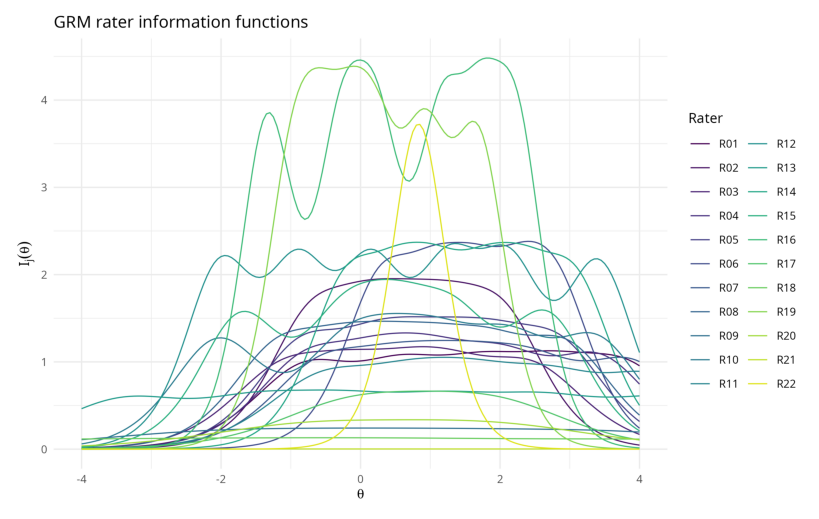

In [10]:
#| label: fig-grm-rater-information
#| fig-cap: "Rater information functions of the graded response model."
show_png("grm/figures/grm_rater_information.png")

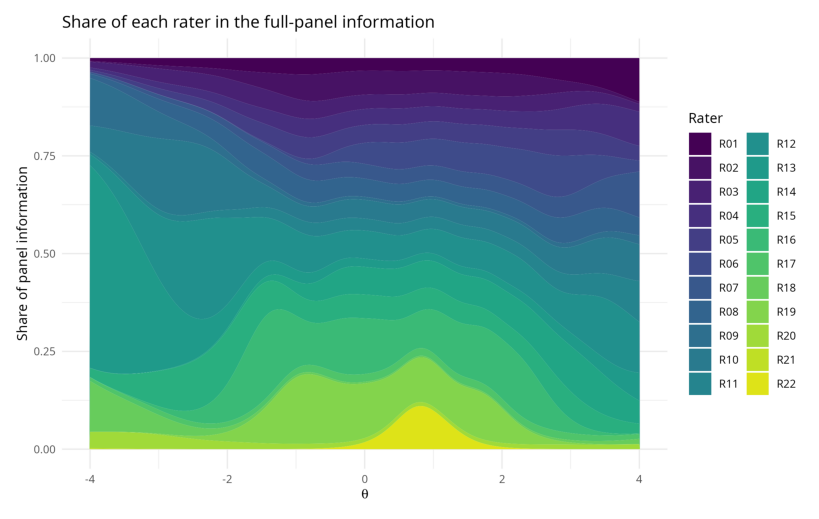

In [11]:
#| label: fig-grm-information-shares
#| fig-cap: "Share of each rater in the information of the full panel across the latent continuum."
show_png("grm/figures/grm_rater_information_shares.png")

In [12]:
#| label: tbl-grm-information-summary
#| tbl-cap: "Rater information summary: information integrated over N(0, 1), location and height of the maximum, and share of the full-panel information (weighted over N(0, 1) and at selected theta)."
show_table("grm/rater_information_summary.csv")

| rater_id   |   n_ratings |   info_weighted_area |   theta_at_max |   info_max |   share_weighted |   share_at_theta_-2 |   share_at_theta_-1 |   share_at_theta_+0 |   share_at_theta_+1 |   share_at_theta_+2 |
|:-----------|------------:|---------------------:|---------------:|-----------:|-----------------:|--------------------:|--------------------:|--------------------:|--------------------:|--------------------:|
| R01        |        1174 |                0.978 |          2.700 |      1.127 |            0.035 |               0.029 |               0.042 |               0.032 |               0.032 |               0.038 |
| R02        |         873 |                1.683 |          0.450 |      1.953 |            0.060 |               0.023 |               0.062 |               0.061 |               0.057 |               0.060 |
| R03        |         720 |                1.080 |          0.900 |      1.174 |            0.039 |               0.047 |               0.048 |               0.037 |               0.034 |               0.036 |
| R04        |         620 |                1.160 |          0.650 |      1.332 |            0.041 |               0.029 |               0.046 |               0.041 |               0.039 |               0.041 |
| R05        |         633 |                1.334 |          0.750 |      1.517 |            0.048 |               0.032 |               0.054 |               0.046 |               0.045 |               0.051 |
| R06        |         520 |                1.398 |          2.400 |      2.381 |            0.050 |               0.001 |               0.009 |               0.054 |               0.068 |               0.080 |
| R07        |         547 |                1.055 |          1.200 |      1.246 |            0.038 |               0.020 |               0.037 |               0.038 |               0.037 |               0.042 |
| R08        |         522 |                1.368 |          0.300 |      1.466 |            0.049 |               0.057 |               0.060 |               0.047 |               0.043 |               0.047 |
| R09        |         400 |                0.239 |          0.100 |      0.242 |            0.009 |               0.022 |               0.011 |               0.008 |               0.007 |               0.008 |
| R10        |         383 |                1.335 |          0.550 |      1.555 |            0.048 |               0.128 |               0.040 |               0.048 |               0.045 |               0.049 |
| R11        |         369 |                0.880 |          1.200 |      1.052 |            0.031 |               0.020 |               0.032 |               0.031 |               0.031 |               0.034 |
| R12        |         264 |                2.147 |          1.350 |      2.356 |            0.077 |               0.221 |               0.101 |               0.072 |               0.063 |               0.080 |
| R13        |         254 |                0.663 |         -0.550 |      0.678 |            0.024 |               0.061 |               0.030 |               0.021 |               0.019 |               0.022 |
| R14        |         259 |                1.762 |          0.800 |      2.371 |            0.063 |               0.005 |               0.030 |               0.071 |               0.069 |               0.081 |
| R15        |          73 |                1.684 |          0.350 |      1.945 |            0.060 |               0.137 |               0.057 |               0.061 |               0.055 |               0.048 |
| R16        |          52 |                3.588 |          1.800 |      4.482 |            0.128 |               0.097 |               0.135 |               0.142 |               0.111 |               0.152 |
| R17        |          52 |                0.544 |          0.950 |      0.665 |            0.019 |               0.013 |               0.017 |               0.020 |               0.020 |               0.021 |
| R18        |          55 |                0.129 |         -0.450 |      0.131 |            0.005 |               0.013 |               0.006 |               0.004 |               0.004 |               0.004 |
| R19        |          50 |                3.628 |         -0.100 |      4.388 |            0.129 |               0.025 |               0.169 |               0.140 |               0.114 |               0.088 |
| R20        |          13 |                0.314 |          0.750 |      0.337 |            0.011 |               0.019 |               0.013 |               0.011 |               0.010 |               0.011 |
| R21        |           9 |                0.002 |          2.250 |      0.002 |            0.000 |               0.000 |               0.000 |               0.000 |               0.000 |               0.000 |
| R22        |           2 |                1.051 |          0.850 |      3.721 |            0.038 |               0.000 |               0.001 |               0.018 |               0.099 |               0.005 |

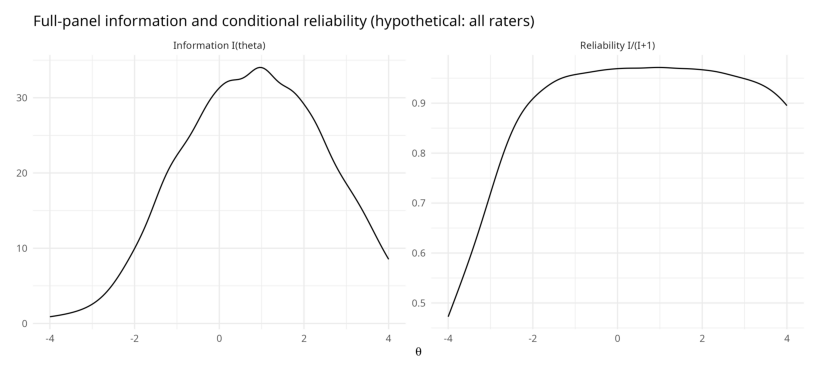

In [13]:
#| label: fig-grm-panel-information
#| fig-cap: "Information and conditional reliability I/(I+1) of the full panel. The curve is hypothetical: it applies to a product rated by all raters."
show_png("grm/figures/grm_panel_information_reliability.png")

In [14]:
#| label: tbl-grm-reliability-summary
#| tbl-cap: "Reliability of the GRM scores: empirical marginal reliability of the actual EAP scores (primary), model-based marginal reliability of the hypothetical full panel, distribution of the product-level reliability rel_post = 1 - PSD^2, and its agreement with the information-based rel_info."
show_table("grm/reliability_summary.csv")

| quantity                                                        |   value |
|:----------------------------------------------------------------|--------:|
| empirical_marginal_reliability (primary; actual scores)         |   0.672 |
| model_based_marginal_reliability_mirt (hypothetical full panel) |   0.962 |
| model_based_marginal_reliability_grid (check)                   |   0.962 |
| var_theta_eap                                                   |   0.672 |
| mean_psd_squared                                                |   0.328 |
| rel_post_min                                                    |   0.001 |
| rel_post_p10                                                    |   0.483 |
| rel_post_q1                                                     |   0.595 |
| rel_post_median                                                 |   0.698 |
| rel_post_q3                                                     |   0.769 |
| rel_post_p90                                                    |   0.814 |
| rel_post_max                                                    |   0.928 |
| rel_post_mean                                                   |   0.672 |
| rel_post_iqr                                                    |   0.173 |
| consistency_cor_rel_post_rel_info                               |   0.935 |
| consistency_mean_diff_rel_info_minus_rel_post                   |   0.016 |
| consistency_max_abs_diff                                        |   0.413 |
| products_abs_diff_gt_0.1                                        | 320.000 |

In [15]:
#| label: tbl-grm-reliability-by-n
#| tbl-cap: "Product-level reliability and posterior SD by number of ratings per product."
show_table("grm/reliability_by_n_ratings.csv")

|   n_ratings |   n_products |   rel_post_mean |   rel_post_median |   rel_info_mean |   psd_mean |
|------------:|-------------:|----------------:|------------------:|----------------:|-----------:|
|       1.000 |      898.000 |           0.519 |             0.553 |           0.543 |      0.687 |
|       2.000 |     2080.000 |           0.698 |             0.714 |           0.713 |      0.544 |
|       3.000 |      357.000 |           0.757 |             0.767 |           0.767 |      0.487 |
|       4.000 |      123.000 |           0.810 |             0.826 |           0.818 |      0.430 |
|       5.000 |      118.000 |           0.822 |             0.834 |           0.833 |      0.418 |
|       6.000 |       50.000 |           0.838 |             0.837 |           0.844 |      0.398 |
|       7.000 |       25.000 |           0.871 |             0.882 |           0.875 |      0.355 |
|       8.000 |        9.000 |           0.872 |             0.889 |           0.872 |      0.350 |
|       9.000 |        6.000 |           0.885 |             0.898 |           0.894 |      0.334 |
|      10.000 |        2.000 |           0.918 |             0.918 |           0.913 |      0.286 |
|      12.000 |        1.000 |           0.923 |             0.923 |           0.927 |      0.278 |

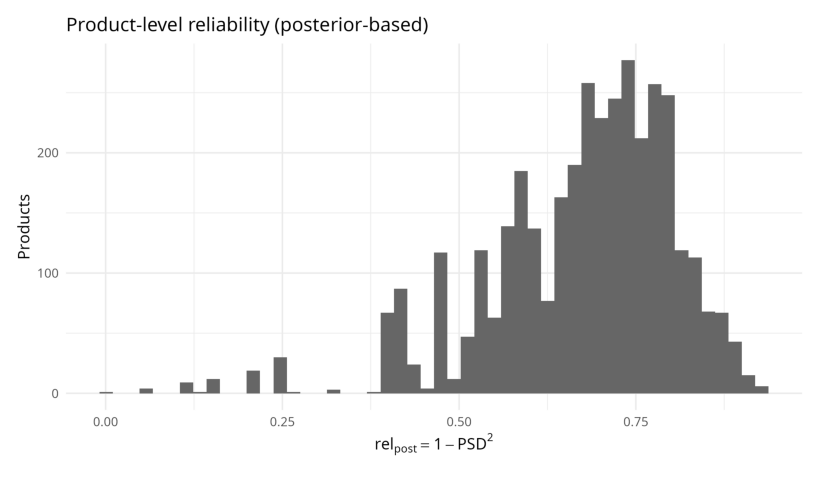

In [16]:
#| label: fig-grm-rel-post-histogram
#| fig-cap: "Distribution of the product-level reliability rel_post across all products."
show_png("grm/figures/grm_rel_post_histogram.png")

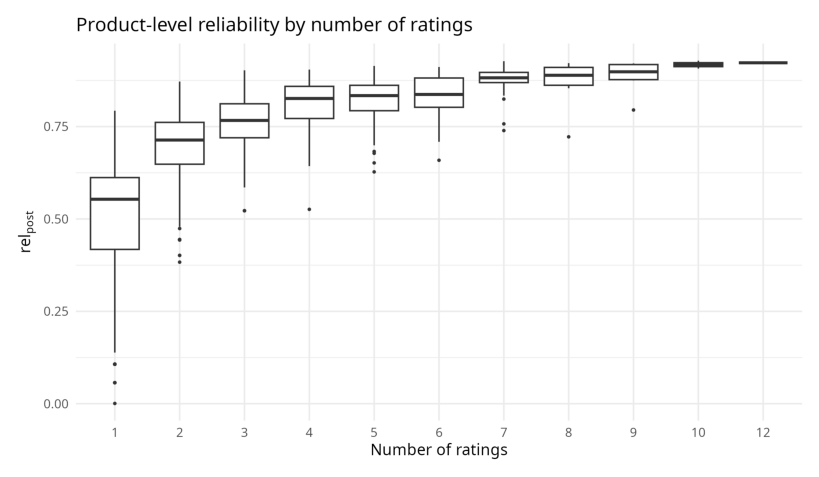

In [17]:
#| label: fig-grm-rel-post-by-n
#| fig-cap: "Product-level reliability rel_post by number of ratings per product."
show_png("grm/figures/grm_rel_post_by_n_ratings.png")

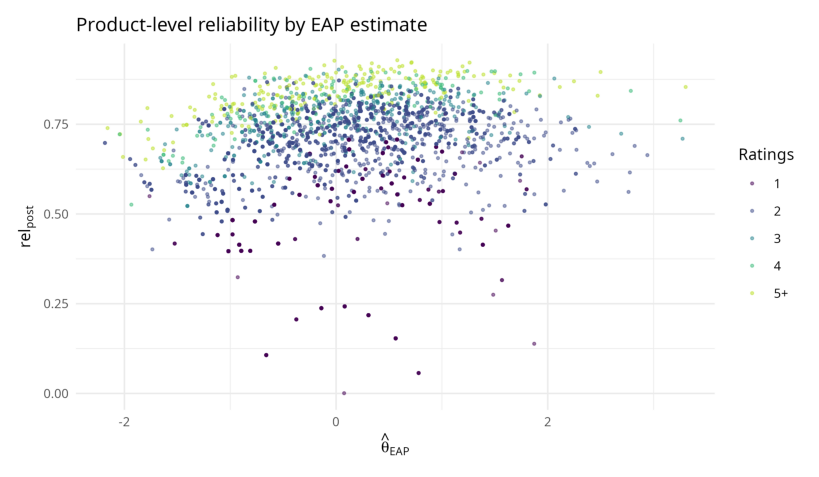

In [18]:
#| label: fig-grm-rel-post-by-theta
#| fig-cap: "Product-level reliability rel_post by EAP estimate."
show_png("grm/figures/grm_rel_post_by_theta.png")

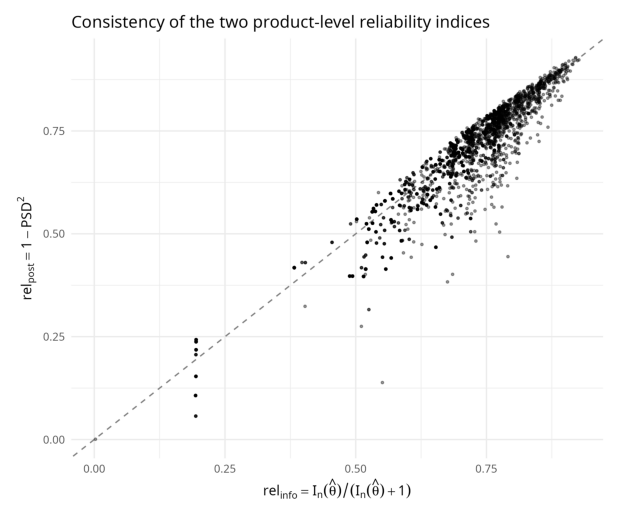

In [19]:
#| label: fig-grm-rel-consistency
#| fig-cap: "Agreement of the two product-level reliability indices: rel_info (information of the product's own raters at the EAP estimate) and rel_post (1 - PSD^2)."
show_png("grm/figures/grm_rel_consistency.png", width=6)

## 4. Comparison: model ladder and MFRM

In [20]:
#| label: tbl-model-fit
#| tbl-cap: "Fit of the adjacent-category ladder (M1 rating scale model / MFRM, M2 partial credit model, M3 generalized partial credit model) and the graded response model: log-likelihood, number of parameters and information criteria."
show_table("comparison/model_fit.csv", lambda d: d[d["status"] == "estimated"][["model", "software", "family", "logLik", "npar", "AIC", "BIC", "SABIC"]])

| model   | software        | family                        |     logLik |    npar |       AIC |       BIC |     SABIC |
|:--------|:----------------|:------------------------------|-----------:|--------:|----------:|----------:|----------:|
| M1_RSM  | sirt::rm.facets | adjacent category             | -12229.578 |  28.000 | 24515.156 | 24688.971 | 24600.001 |
| M2_PCM  | mirt            | adjacent category             | -11852.865 | 118.000 | 23941.731 | 24674.236 | 24299.290 |
| M3_GPCM | mirt            | adjacent category             | -11788.969 | 139.000 | 23855.939 | 24718.805 | 24277.132 |
| GRM     | mirt            | cumulative (not in LR ladder) | -11765.852 | 139.000 | 23809.703 | 24672.570 | 24230.896 |

In [21]:
#| label: tbl-lr-tests
#| tbl-cap: "Likelihood-ratio tests within the adjacent-category ladder."
show_table("comparison/lr_tests.csv", lambda d: d[["comparison", "X2", "df", "df_expected_formula", "p"]])

| comparison                               |      X2 |   df |   df_expected_formula |     p |
|:-----------------------------------------|--------:|-----:|----------------------:|------:|
| M1 vs M2: rater-specific thresholds      | 753.426 |   90 |                   105 | 0.000 |
| M2 vs M3: rater-specific discriminations | 127.792 |   21 |                    21 | 0.000 |

In [22]:
#| label: tbl-theta-correlations
#| tbl-cap: "Correlations of the EAP estimates between models (Pearson and Spearman)."
show_table("comparison/theta_correlations.csv")

| method   | model                  |   M1_RSM |   M2_PCM |   M3_GPCM |   GRM |   rm_facets_default_grid |
|:---------|:-----------------------|---------:|---------:|----------:|------:|-------------------------:|
| pearson  | M1_RSM                 |    1.000 |    0.993 |     0.980 | 0.975 |                    1.000 |
| pearson  | M2_PCM                 |    0.993 |    1.000 |     0.988 | 0.984 |                    0.993 |
| pearson  | M3_GPCM                |    0.980 |    0.988 |     1.000 | 0.996 |                    0.980 |
| pearson  | GRM                    |    0.975 |    0.984 |     0.996 | 1.000 |                    0.975 |
| pearson  | rm_facets_default_grid |    1.000 |    0.993 |     0.980 | 0.975 |                    1.000 |
| spearman | M1_RSM                 |    1.000 |    0.996 |     0.982 | 0.978 |                    1.000 |
| spearman | M2_PCM                 |    0.996 |    1.000 |     0.987 | 0.982 |                    0.996 |
| spearman | M3_GPCM                |    0.982 |    0.987 |     1.000 | 0.996 |                    0.982 |
| spearman | GRM                    |    0.978 |    0.982 |     0.996 | 1.000 |                    0.978 |
| spearman | rm_facets_default_grid |    1.000 |    0.996 |     0.982 | 0.978 |                    1.000 |

In [23]:
#| label: tbl-discrimination-m3
#| tbl-cap: "Rater discriminations in the generalized partial credit model (M3)."
show_table("comparison/discrimination_m3.csv", lambda d: d[["rater_id", "n_ratings", "estimate", "se"]])

| rater_id   |   n_ratings |   estimate |     se |
|:-----------|------------:|-----------:|-------:|
| R22        |           2 |     -4.624 | 10.659 |
| R21        |           9 |     -0.099 |  0.528 |
| R09        |         400 |      0.284 |  0.055 |
| R18        |          55 |      0.323 |  0.148 |
| R20        |          13 |      0.474 |  0.329 |
| R17        |          52 |      0.616 |  0.235 |
| R13        |         254 |      0.869 |  0.160 |
| R11        |         369 |      0.897 |  0.145 |
| R03        |         720 |      0.983 |  0.142 |
| R04        |         620 |      1.000 |  0.187 |
| R07        |         547 |      1.021 |  0.137 |
| R05        |         633 |      1.089 |  0.152 |
| R08        |         522 |      1.107 |  0.198 |
| R02        |         873 |      1.181 |  0.261 |
| R01        |        1174 |      1.300 |  0.130 |
| R15        |          73 |      1.361 |  0.402 |
| R10        |         383 |      1.373 |  0.321 |
| R14        |         259 |      1.434 |  0.461 |
| R06        |         520 |      1.969 |  0.397 |
| R12        |         264 |      2.416 |  0.703 |
| R19        |          50 |      2.455 |  2.072 |
| R16        |          52 |      2.977 |  1.803 |

In [24]:
#| label: tbl-threshold-order
#| tbl-cap: "Raters with unordered step parameters in M2 (PCM) and M3 (GPCM)."
show_table("comparison/threshold_order.csv", lambda d: d[~d["ordered"]])

| model   | rater_id   |   n_steps | ordered   |   n_reversals | steps                            |
|:--------|:-----------|----------:|:----------|--------------:|:---------------------------------|
| M2_PCM  | R03        |         5 | False     |             1 | -0.86;-0.21;1.11;0.68;2.63       |
| M2_PCM  | R04        |         6 | False     |             1 | -0.54;0.58;0.67;0.52;2.17;3.76   |
| M2_PCM  | R05        |         6 | False     |             1 | -0.73;0.62;0.58;1.46;1.80;2.71   |
| M2_PCM  | R06        |         5 | False     |             1 | 0.92;1.25;1.59;2.84;2.37         |
| M2_PCM  | R11        |         6 | False     |             1 | -0.35;0.96;1.06;0.93;2.65;4.14   |
| M2_PCM  | R15        |         6 | False     |             2 | -2.16;0.35;0.35;0.15;1.28;3.11   |
| M2_PCM  | R16        |         6 | False     |             1 | -2.06;0.20;-0.19;1.80;1.87;1.98  |
| M2_PCM  | R17        |         4 | False     |             2 | 0.50;0.17;1.29;0.98              |
| M2_PCM  | R19        |         6 | False     |             2 | -0.42;-0.85;0.10;-0.29;1.21;1.75 |
| M2_PCM  | R20        |         4 | False     |             2 | 0.75;-1.37;1.18;0.80             |
| M2_PCM  | R21        |         4 | False     |             1 | -1.40;-0.51;1.38;-0.15           |
| M3_GPCM | R03        |         5 | False     |             1 | -0.81;-0.19;1.11;0.65;2.59       |
| M3_GPCM | R04        |         6 | False     |             1 | -0.53;0.58;0.66;0.48;2.12;3.68   |
| M3_GPCM | R05        |         6 | False     |             1 | -0.69;0.58;0.56;1.39;1.72;2.58   |
| M3_GPCM | R06        |         5 | False     |             1 | 0.50;1.06;1.46;2.29;2.27         |
| M3_GPCM | R09        |         6 | False     |             2 | -0.43;-0.78;0.63;-0.12;1.10;3.92 |
| M3_GPCM | R11        |         6 | False     |             1 | -0.29;1.09;1.14;0.94;2.78;4.31   |
| M3_GPCM | R15        |         6 | False     |             1 | -1.92;0.21;0.34;0.27;1.21;2.83   |
| M3_GPCM | R17        |         4 | False     |             2 | 1.12;0.22;1.74;0.82              |
| M3_GPCM | R18        |         5 | False     |             1 | -7.07;-2.09;0.40;-0.67;4.87      |
| M3_GPCM | R20        |         4 | False     |             2 | 2.48;-2.89;1.88;0.68             |
| M3_GPCM | R21        |         4 | False     |             2 | 7.28;4.31;-10.89;7.08            |

In [25]:
#| label: tbl-rater-fit-m1
#| tbl-cap: "Rater infit and outfit mean squares under M1 (rating scale model / MFRM)."
show_table("comparison/rater_fit_m1.csv", lambda d: d[["rater_id", "n_ratings", "infit", "outfit"]])

| rater_id   |   n_ratings |   infit |   outfit |
|:-----------|------------:|--------:|---------:|
| R01        |        1174 |   0.466 |    0.481 |
| R02        |         873 |   0.785 |    0.782 |
| R03        |         720 |   0.581 |    0.580 |
| R04        |         620 |   0.685 |    0.659 |
| R05        |         633 |   0.703 |    0.672 |
| R06        |         520 |   0.908 |    0.707 |
| R07        |         547 |   0.824 |    0.750 |
| R08        |         522 |   0.540 |    0.548 |
| R09        |         400 |   0.976 |    0.957 |
| R10        |         383 |   0.406 |    0.389 |
| R11        |         369 |   0.936 |    0.873 |
| R12        |         264 |   0.238 |    0.254 |
| R13        |         254 |   0.398 |    0.399 |
| R14        |         259 |   0.746 |    0.694 |
| R15        |          73 |   0.739 |    0.687 |
| R16        |          52 |   0.453 |    0.460 |
| R17        |          52 |   1.324 |    1.189 |
| R18        |          55 |   0.991 |    1.047 |
| R19        |          50 |   0.654 |    0.700 |
| R20        |          13 |   1.417 |    1.387 |
| R21        |           9 |   1.242 |    1.259 |
| R22        |           2 |   0.749 |    0.749 |

In [26]:
#| label: tbl-marginal-reliability-models
#| tbl-cap: "Marginal and empirical reliability by model, for comparison."
show_table("comparison/marginal_reliability.csv")

| model   |   latent_variance |   marginal_reliability |   marginal_rxx_mirt |   empirical_rxx |
|:--------|------------------:|-----------------------:|--------------------:|----------------:|
| M1_RSM  |             0.951 |                  0.950 |             nan     |           0.625 |
| M2_PCM  |             1.077 |                  0.949 |             nan     |           0.636 |
| M3_GPCM |             1.000 |                  0.958 |               0.958 |           0.657 |
| GRM     |             1.000 |                  0.962 |               0.962 |           0.672 |

## 5. Naive indices and overview

In [27]:
def naive_indices():
    cr, ka = read_res("naive/cronbach_alpha.csv"), read_res("naive/krippendorff_alpha.csv")
    if cr is None or ka is None:
        return None
    return pd.concat([
        pd.DataFrame({"index": "Cronbach's alpha: " + cr["variant"], "value": cr["raw_alpha"],
                      "ci_low": None, "ci_high": None, "n_raters": cr["n_raters"],
                      "n_products": cr["n_products_contributing"]}),
        pd.DataFrame({"index": "Krippendorff's alpha (ordinal)", "value": ka["alpha"],
                      "ci_low": ka["ci_low"], "ci_high": ka["ci_high"], "n_raters": ka["n_raters"],
                      "n_products": ka["n_pairable_units"]}),
    ], ignore_index=True)

In [28]:
#| label: tbl-naive-indices
#| tbl-cap: "Cronbach's alpha (consistency of the unweighted rater mean) and Krippendorff's alpha (ordinal agreement of single ratings, 95% bootstrap CI over products)."
_naive = naive_indices()
_missing("naive/*.csv") if _naive is None else Markdown(_naive.to_markdown(index=False, floatfmt=".3f"))

| index                                                     |   value |   ci_low |   ci_high |   n_raters |   n_products |
|:----------------------------------------------------------|--------:|---------:|----------:|-----------:|-------------:|
| Cronbach's alpha: pairwise covariances, all usable raters |   0.928 |          |           |         14 |         1900 |
| Cronbach's alpha: fully crossed block (listwise complete) |   0.658 |          |           |          3 |          139 |
| Krippendorff's alpha (ordinal)                            |   0.391 |    0.361 |     0.418 |         22 |         2771 |

In [29]:
#| label: tbl-reliability-overview
#| tbl-cap: "Overview of the reliability and agreement indices and what each refers to."
show_table("summary/reliability_overview.csv")

| index                                   | refers_to                                                 |   value | ci_or_note                                          |
|:----------------------------------------|:----------------------------------------------------------|--------:|:----------------------------------------------------|
| Krippendorff's alpha (ordinal)          | consensus of single ratings                               |   0.391 | 95% bootstrap CI [0.361, 0.418], 1000 replications  |
| Cronbach's alpha (pairwise covariances) | consistency of the unweighted rater mean                  |   0.928 | 14 raters; removed: R22;R19;R21;R14;R16;R02;R12;R20 |
| Cronbach's alpha (fully crossed block)  | consistency of the unweighted rater mean (crossed subset) |   0.658 | 3 raters, 139 products                              |
| GRM: empirical marginal reliability     | actual theta_hat (primary)                                |   0.672 | Var(theta)/(Var(theta)+mean(PSD^2))                 |
| GRM: model-based marginal reliability   | hypothetical full panel                                   |   0.962 | mirt::marginal_rxx, all raters                      |
| GRM: median rel_post                    | precision per product                                     |   0.698 | Q1 0.595, Q3 0.769                                  |
| GRM: IQR rel_post                       | precision per product                                     |   0.173 | nan                                                 |
| M1 (RSM): marginal reliability          | comparison                                                |   0.950 | nan                                                 |
| M2 (PCM): marginal reliability          | comparison                                                |   0.949 | nan                                                 |
| M3 (GPCM): marginal reliability         | comparison                                                |   0.958 | nan                                                 |